## Lab 9  
**Text Analysis for Product Reviews: Reproducible Preprocessing, TF–IDF, Sentiment Classification, Topic Modeling, and System-Aware Diagnostics**

## Learning Objectives

In this lab, you will implement a classical end-to-end text-analysis workflow for product-review sentences. You will validate the corpus, design task-aware preprocessing, compare count and TF–IDF features, build lexicon-based and learning-based sentiment models, interpret topic-model outputs, and discuss how to monitor such a system in production.


By the end of this lab, you will be able to:

1. **Implement** a reproducible text-analysis workflow for labeled review sentences using Python and scikit-learn.
2. **Validate** a raw text corpus using schema checks, missingness audits, duplicate detection, and label sanity checks.
3. **Compare** count-based and TF–IDF-based text representations and **interpret** the effect of n-grams on context capture.
4. **Compute** TF–IDF on a small corpus by hand and **verify** the result with `TfidfVectorizer`.
5. **Evaluate** lexicon-based and supervised sentiment models and **debug** common failure modes such as negation and domain mismatch.
6. **Interpret** NMF topic-model outputs using top terms, exemplar documents, and sentiment-by-topic summaries.
7. **Monitor** reproducibility, leakage risk, vocabulary drift, and inference-time tradeoffs in a text ML system.

## Tasks

- Load the Amazon review sentence dataset and document its schema and metadata.
- Audit the corpus for missing text, duplicates, label balance, and basic text-length patterns.
- Build a task-aware preprocessing function that preserves negation and masks structured noise.
- Construct count and TF–IDF features and inspect vocabulary growth and phrase features.
- Compute TF–IDF manually on a toy corpus and compare it with library output.
- Implement a lexicon-based sentiment baseline and analyze its failures.
- Train a supervised TF–IDF + Logistic Regression sentiment classifier.
- Improve the classifier with n-grams and vocabulary filtering, then compare metrics.
- Diagnose model behavior using confusion matrices, influential features, and error analysis.
- Fit an NMF topic model and generate topic labels, exemplar documents, and sentiment-by-topic summaries.

**Note:** In this programming lab, you are required to execute all cells step by step and focus on understanding the methodology and the outcomes at each step. Answering the questions included in this lab (pre-coding and post-execution interpretation questions) is optional and is not required for the completion of the programming lab.

## References

### Official Documentation

- `pandas.read_csv`  
  https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html
- `re.sub`  
  https://docs.python.org/3/library/re.html
- `nltk.tokenize.word_tokenize`  
  https://www.nltk.org/api/nltk.tokenize.word_tokenize.html
- `nltk.corpus.stopwords`  
  https://www.nltk.org/
- `sklearn.model_selection.train_test_split`  
  https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
- `sklearn.feature_extraction.text.CountVectorizer`  
  https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html
- `sklearn.feature_extraction.text.TfidfVectorizer`  
  https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html
- `sklearn.pipeline.Pipeline`  
  https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html
- `sklearn.linear_model.LogisticRegression`  
  https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
- `sklearn.metrics.classification_report`  
  https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html
- `sklearn.metrics.confusion_matrix`  
  https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html
- `sklearn.decomposition.NMF`  
  https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.NMF.html
- `sklearn.metrics.pairwise.cosine_similarity`  
  https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.cosine_similarity.html

### References

- scikit-learn User Guide: Working with text data  
  https://scikit-learn.org/stable/tutorial/text_analytics/working_with_text_data.html
- NLTK Book  
  https://www.nltk.org/book/

### Python Commands / Quick Reference

`pd.read_csv`, `df.isna()`, `df.duplicated()`, `value_counts()`, `str.len()`, `re.sub()`, `word_tokenize()`, `stopwords.words()`, `train_test_split()`, `CountVectorizer()`, `TfidfVectorizer()`, `Pipeline()`, `LogisticRegression()`, `classification_report()`, `confusion_matrix()`, `cosine_similarity()`, `NMF()`

## Workflow Overview

1. Set up imports, seeds, versions, and reproducibility controls.
2. Download and load the Amazon review corpus directly from the public source.
3. Validate schema, labels, duplicates, missingness, and basic corpus statistics.
4. Build a preprocessing function with regex cleaning, lowercasing, tokenization, and negation-aware stopword handling.
5. Create count and TF–IDF representations, then compute TF–IDF manually on a toy corpus.
6. Implement a lexicon-based sentiment baseline and inspect failure cases.
7. Train a TF–IDF + Logistic Regression sentiment baseline using a leakage-safe split.
8. Improve the classifier with bigrams and vocabulary filtering; analyze features and misclassifications.
9. Fit an NMF topic model, inspect top terms and exemplar documents, and label topics.
10. Compute sentiment-by-topic, summarize limitations, and discuss monitoring, drift, and deployment concerns


## Dataset

**Primary dataset:** UCI Sentiment Labelled Sentences — Amazon subset

- **Dataset name:** Sentiment Labelled Sentences (Amazon subset)
- **Direct download link:**  
  https://archive.ics.uci.edu/ml/machine-learning-databases/00331/sentiment%20labelled%20sentences.zip
- **Dataset page:**  
  https://archive.ics.uci.edu/ml/datasets/Sentiment+Labelled+Sentences
- **Description:** 1000 Amazon product-review sentences labeled for sentiment
- **Features:** `text`
- **Target:** `label` where `0 = negative`, `1 = positive`
- **Size:** 1000 rows, 2 columns after loading
- **Usage note:** This dataset is widely used academic benchmark; suitable for instructional and experimental purposes

### Step 1 — Setup & Reproducibility

### Pre-coding questions

1. If two students run the same notebook with different `random_state` values, which outputs are most likely to change and why?     
The train/test split can be altered, so several reviews can be placed in either the training set or the test set. This can affect the coefficients learned by the model, the model's predictions, accuracy, F1 score, and confusion matrix, and potentially the result of a topic-model analysis. Changing the random state will lead to different random decisions in the experiment.


2. Why might a notebook still produce different results across machines even if the seed is fixed?      
Different Python, pandas, NumPy, scikit-learn, or NLTK versions can produce slightly different results. Additionally, differences in the operating system, implementations of libraries, downloaded resources, random number generators, or any other incidental factors can contribute to differing results. The use of a single seed only affects randomly generated numbers, and only those, which may not be all sources of randomness.


3. What should be logged so that this experiment can be reproduced later?       
The Python version, operating system, package versions, random seed, dataset source and version, preprocessing settings, train/test split settings, vectorizer parameters, model parameters, and important output metrics should be logged. The exact code and configuration should also be saved.



### Function/class selection and parameter exploration

Use:

- `numpy.random.seed`
- `sklearn.model_selection.train_test_split`
- `sklearn.pipeline.Pipeline`

Explore with `help()` or notebook `?`:

- `train_test_split(test_size, stratify, random_state, shuffle)`
- `Pipeline(steps=...)`

Explain the effect of:

- `random_state` on reproducibility
- `test_size` on evaluation variance and training data size
- `stratify` on label balance and evaluation validity
- `shuffle` on split behavior and when it may be inappropriate for time-ordered data

In [2]:
%pip install -q -U nltk wordcloud

Note: you may need to restart the kernel to use updated packages.


In [3]:
# Step 1: Setup & reproducibility
import io
import re
import zipfile
import urllib.request
import sys
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import NMF

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords, opinion_lexicon

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("opinion_lexicon")

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("pandas:", pd.__version__)
print("Random state:", RANDOM_STATE)

Python: 3.13.9
Platform: Windows-11-10.0.26200-SP0
pandas: 2.3.3
Random state: 42


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\giova\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\giova\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\giova\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\giova\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package opinion_lexicon to
[nltk_data]     C:\Users\giova\AppData\Roaming\nltk_data...
[nltk_data]   Package opinion_lexicon is already up-to-date!


**Think like an ML Systems engineer:**  
How would you make this experiment reproducible across machines, semesters, and retraining runs?        
I would record the dataset source, random seed, Python and package versions, preprocessing settings, model parameters, and evaluation results. I would also save the notebook and trained pipeline so that the same preprocessing and model configuration can be reused later.



### Post-execution interpretation questions

1. Which environment details shown above are most important for reproducibility?    
The Python version, platform, pandas version, and random state are especially important. The versions of scikit-learn, NumPy, NLTK, and other libraries used by the notebook are also important.


2. Why is it risky to record versions only after the modeling phase?        
If versions are only recorded afterward, the experiment may already have been affected by differences that were not documented. It becomes harder to determine why results changed or reproduce the original experiment.

### Step 2 — Data Acquisition

### Pre-coding questions

1. Why is direct programmatic loading preferable to relying on hidden local files in an instructional notebook?        
Programmatic loading makes the data source explicit and allows another person to reproduce the experiment without needing a particular local file or folder structure. It also reduces problems caused by missing or outdated local files. 

 
2. What risk arises if the original text is overwritten during cleaning instead of preserving a raw copy?           
Important information may be permanently removed, making it impossible to go back and inspect the original reviews. It also makes debugging preprocessing problems harder because there is no raw version to compare against.


3. Why can a balanced benchmark dataset still be a poor proxy for production traffic?       
A balanced benchmark may not represent the types of reviews, writing styles, product categories, slang, misspellings, or class frequencies found in real production data. Production traffic can also change over time, causing distribution drift.



### Function/class selection and parameter exploration

Use:

- `urllib.request.urlopen`
- `zipfile.ZipFile`
- `pandas.read_csv`

Explore:

- `pd.read_csv(sep, header, names, encoding)`
- `ZipFile.namelist()`

Explain the effect of:

- `sep="\t"` on parsing correctness
- `names=["text", "label"]` on schema clarity
- `encoding` on robustness to text corruption

In [4]:
# Step 2: Download and load the Amazon subset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00331/sentiment%20labelled%20sentences.zip"

with urllib.request.urlopen(url) as response:
    zip_bytes = response.read()

with zipfile.ZipFile(io.BytesIO(zip_bytes)) as zf:
    target_name = None
    for name in zf.namelist():
        if name.lower().endswith("amazon_cells_labelled.txt"):
            target_name = name
            break
    if target_name is None:
        raise FileNotFoundError("amazon_cells_labelled.txt not found in zip archive.")

    raw_file = zf.read(target_name).decode("utf-8")

df = pd.read_csv(
    io.StringIO(raw_file),
    sep="\t",
    header=None,
    names=["text", "label"]
)

print("Shape:", df.shape)
print(df.head(5).to_string(index=False))

Shape: (1000, 2)
                                                                              text  label
So there is no way for me to plug it in here in the US unless I go by a converter.      0
                                                       Good case, Excellent value.      1
                                                            Great for the jawbone.      1
   Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!      0
                                                                 The mic is great.      1


### Post-execution interpretation questions

1. What evidence suggests the dataset loaded correctly?         
The dataset should have the expected shape of 1000 rows and 2 columns, with columns named text and label. The labels should contain only 0 and 1, and the displayed first few rows should contain review sentences and their corresponding sentiment labels. The lab identifies 0 as negative and 1 as positive.


2. What additional metadata would be necessary to study topic prevalence over time?         
The dataset would need a timestamp such as the review date or publication date. It would also be useful to have product IDs, product categories, and possibly customer or review IDs.


3. What limitation does this dataset impose on aspect-level analysis?       
The dataset only provides review text and a sentiment label. It does not provide explicit aspect labels, such as whether a review is discussing price, shipping, quality, or customer service. Therefore, aspect-level analysis would require additional annotation or another source of metadata.


### Step 3 — Data Validation & Exploratory Text Analysis

### Pre-coding questions

1. What failure mode occurs if duplicated sentences are split across train and test sets?       
The model may see the exact same sentence during training and testing. This creates data leakage and can make the model's performance look better than it really is on unseen reviews.

 
2. Why are very short documents challenging for both classification and topic modeling?         
Short documents contain very few words, so there is less information available to determine sentiment or topic. Important terms may also be missing, making it harder for a model to distinguish between different classes or themes.

  
3. Which is more dangerous here: duplicate leakage or mild class imbalance? Justify.        
Duplicate leakage is more dangerous because it can directly contaminate the evaluation set with information the model already saw during training. Mild class imbalance can affect metrics, but it can usually be handled with appropriate evaluation metrics such as macro-F1.



### Function/class selection and parameter exploration

Use:

- `DataFrame.isna`
- `DataFrame.duplicated`
- `Series.value_counts`
- `Series.str.len`

Explore:

- `duplicated(subset=..., keep=...)`
- `value_counts(normalize=True)`

Explain the effect of:

- duplicate detection on leakage prevention
- label distribution on metric choice
- length statistics on representation design
- missingness checks on pipeline robustness

        dtype  missing_count  missing_rate  n_unique
text   object              0           0.0       990
label   int64              0           0.0         2
Duplicate review texts: 10

Label balance:
label
0    0.5
1    0.5
Name: proportion, dtype: float64


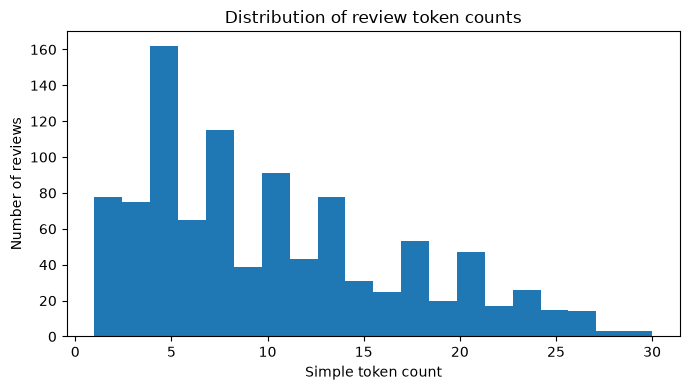

In [5]:
# Step 3: Schema validation and corpus profiling
def corpus_report(dataframe):
    return pd.DataFrame({
        "dtype": dataframe.dtypes.astype(str),
        "missing_count": dataframe.isna().sum(),
        "missing_rate": dataframe.isna().mean(),
        "n_unique": dataframe.nunique(dropna=True)
    })

print(corpus_report(df))

assert {"text", "label"}.issubset(df.columns)
assert df["text"].notna().any()
assert set(df["label"].dropna().unique()) <= {0, 1}

duplicate_count = int(df["text"].duplicated().sum())
print("Duplicate review texts:", duplicate_count)


df["char_len"] = df["text"].astype(str).str.len()
df["token_len_simple"] = df["text"].astype(str).str.split().str.len()

print("\nLabel balance:")
print(df["label"].value_counts(normalize=True).sort_index())

plt.figure(figsize=(7, 4))
plt.hist(df["token_len_simple"], bins=20)
plt.title("Distribution of review token counts")
plt.xlabel("Simple token count")
plt.ylabel("Number of reviews")
plt.tight_layout()
plt.show()

The following section explores the review text data in greater detail. By examining word frequencies and visualizing the text with word clouds and frequency plots, we can gain insights into common themes, vocabulary, and potential issues within the corpus. These analyses help inform decisions about preprocessing, feature selection, and highlight aspects such as repeated phrases or key topics, supporting effective downstream modeling.

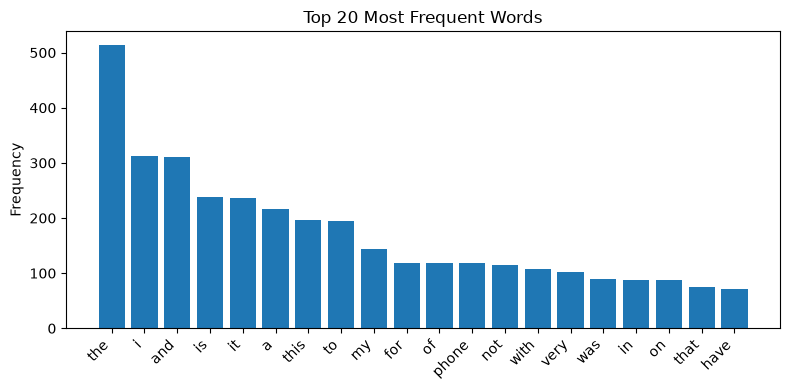

In [23]:
# Additional text analysis: more plots and word cloud

from wordcloud import WordCloud, STOPWORDS
from collections import Counter
import nltk

# Simple word frequency plot
all_text = " ".join(df["text"].dropna().astype(str).values)
tokens = [word.lower() for word in all_text.split()]
token_counts = Counter(tokens)

common_words = token_counts.most_common(20)
words, counts = zip(*common_words)

plt.figure(figsize=(8, 4))
plt.bar(words, counts)
plt.xticks(rotation=45, ha='right')
plt.title("Top 20 Most Frequent Words")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


 introduce the following code and highlight an observation

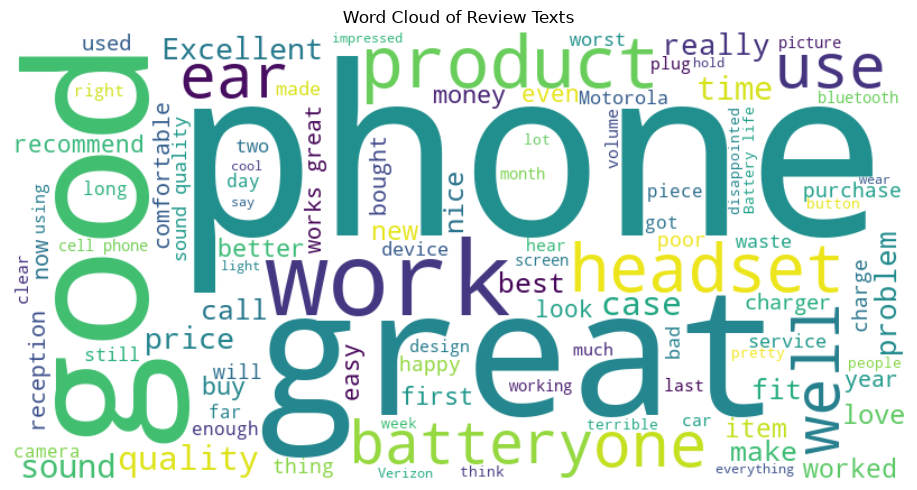

In [7]:

# Word cloud for the full corpus
stopwords_wc = set(STOPWORDS)
wordcloud = WordCloud(
    width=800, height=400,
    background_color="white",
    stopwords=stopwords_wc,
    max_words=100
).generate(all_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.title("Word Cloud of Review Texts")
plt.tight_layout()
plt.show()


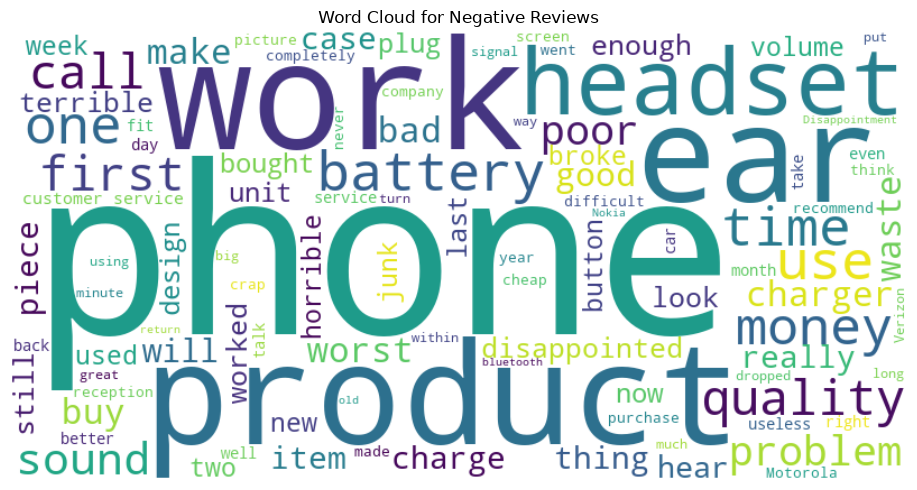

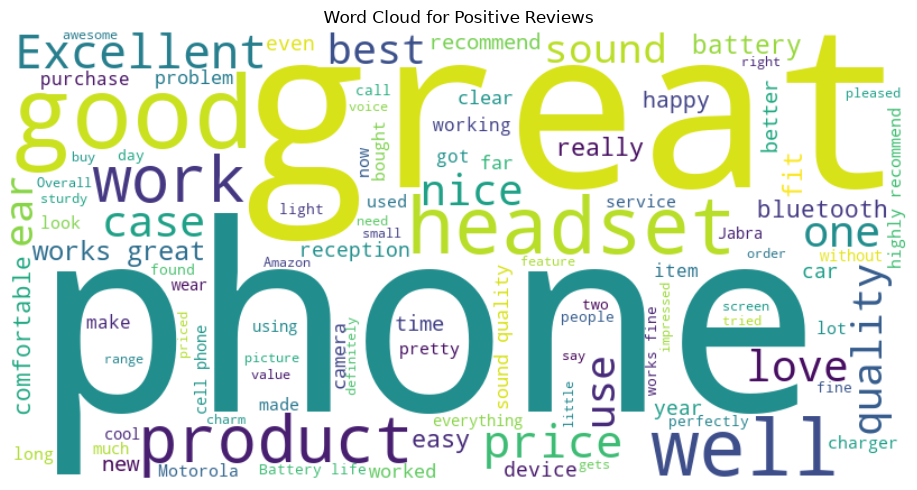

In [8]:

# Word clouds by label (sentiment)
for label_value, label_name in zip([0,1], ['Negative', 'Positive']):
    subset_text = " ".join(df.loc[df["label"] == label_value, "text"].dropna().astype(str).values)
    wordcloud_label = WordCloud(
        width=800, height=400,
        background_color="white",
        stopwords=stopwords_wc,
        max_words=100
    ).generate(subset_text)
    
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud_label, interpolation='bilinear')
    plt.axis("off")
    plt.title(f"Word Cloud for {label_name} Reviews")
    plt.tight_layout()
    plt.show()


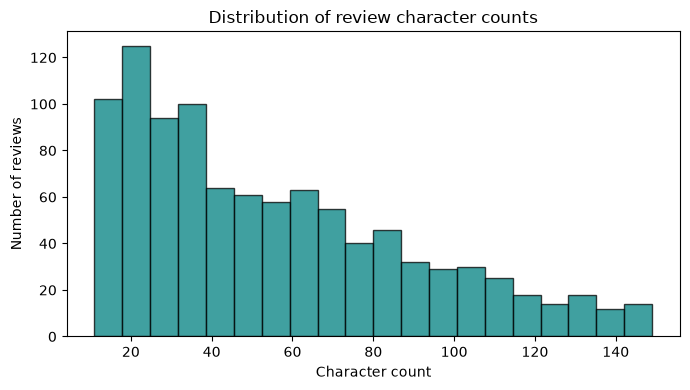

In [9]:

# Average and distribution of character length visual
plt.figure(figsize=(7, 4))
plt.hist(df["char_len"], bins=20, color='teal', edgecolor='k', alpha=0.75)
plt.title("Distribution of review character counts")
plt.xlabel("Character count")
plt.ylabel("Number of reviews")
plt.tight_layout()
plt.show()


**Think like an ML Systems engineer:**  
Where could silent leakage or schema drift appear before the first model is trained?        
Leakage could occur through duplicate reviews, preprocessing performed before the train/test split, or information from the labels entering the features. Schema drift could occur if future data changes column names, data types, missing-value patterns, or text formats.



### Post-execution interpretation questions

1. Does this corpus resemble short-text or long-document analysis?      
It resembles short-text analysis because the dataset contains individual product-review sentences rather than long documents. This means each observation contains relatively little text.

 
2. Why should macro-F1 still be reported even if the classes look balanced?         
Macro-F1 calculates the F1 score for each class and gives them equal importance. It can therefore reveal whether the model performs differently on positive and negative reviews even when the overall class distribution is balanced.


3. If duplicates exist, would you always remove them? What tradeoff arises?         
Not necessarily. Removing duplicates can reduce leakage during evaluation, but duplicates could represent legitimate repeated reviews or repeated language in real production data. The decision should depend on whether the goal is evaluating performance on unique text or modeling the actual production distribution.


### Step 4 — Task-Aware Preprocessing

### Pre-coding questions

1. Why is aggressive stopword removal risky for sentiment classification?       
Some words that are commonly considered stopwords can affect sentiment. In particular, words such as not, no, and never can reverse or change the meaning of a sentence.


2. Why replace URLs or IDs with placeholders instead of deleting them?          
Placeholders preserve the fact that a URL or ID was present without allowing every individual URL or ID to become a separate feature. This keeps potentially useful structural information while reducing vocabulary noise.


3. Which is more damaging for this task: preserving too much noise or deleting negation-bearing tokens?         
Deleting negation-bearing tokens is more damaging because it can completely change the meaning of a review. For example, removing "not" from "not good" could make the remaining phrase appear positive.



### Function/class selection and parameter exploration

Use:

- `re.sub`
- `nltk.tokenize.word_tokenize`
- `nltk.corpus.stopwords.words`

Explore:

- `CountVectorizer(lowercase, stop_words, ngram_range, min_df, max_df)`
- `TfidfVectorizer` with the same parameters

Explain the effect of:

- `lowercase` on vocabulary size
- `ngram_range` on phrase capture and sparsity
- `min_df` on rare-term pruning
- `max_df` on common artifact removal

In [10]:
# Step 4: Preprocessing utilities

import re
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

EN_STOPWORDS = set(stopwords.words("english"))
NEGATION_WORDS = {"not", "no", "never", "nor", "n't"}

custom_stopwords = EN_STOPWORDS - NEGATION_WORDS


def clean_text(text):
    text = str(text).strip().lower()

    text = re.sub(r"https?://\S+|www\.\S+", " <URL> ", text)
    text = re.sub(r"\b[\w\.-]+@[\w\.-]+\.\w+\b", " <EMAIL> ", text)
    text = re.sub(r"\b(?:ord[-_]?\d+|\d{5,})\b", " <ORDER_ID> ", text)

    text = re.sub(r"\s+", " ", text)
    return text

def tokenize_for_lexicon(text, stopword_set=None):
    tokens = word_tokenize(clean_text(text))
    tokens = [tok for tok in tokens if re.search(r"[a-z<>]", tok)]
    if stopword_set is not None:
        tokens = [tok for tok in tokens if tok not in stopword_set]
    return tokens

sample_reviews = df["text"].sample(5, random_state=RANDOM_STATE).tolist()
for i, review in enumerate(sample_reviews, start=1):
    print(f"\nReview {i}: {review}")
    print("Tokens:", tokenize_for_lexicon(review, stopword_set=custom_stopwords))


Review 1: Thanks again to Amazon for having the things I need for a good price!
Tokens: ['thanks', 'amazon', 'things', 'need', 'good', 'price']

Review 2: The tracfonewebsite is user friendly and makes it easy toactivate, etc.
Tokens: ['tracfonewebsite', 'user', 'friendly', 'makes', 'easy', 'toactivate', 'etc']

Review 3: I would highly recommend this product.
Tokens: ['would', 'highly', 'recommend', 'product']

Review 4: This does not fit the Palm Tungsten E2 and it broke the first time I tried to plug it in.
Tokens: ['not', 'fit', 'palm', 'tungsten', 'e2', 'broke', 'first', 'time', 'tried', 'plug']

Review 5: I highly recommend this device to everyone!
Tokens: ['highly', 'recommend', 'device', 'everyone']



### Post-execution interpretation questions

1. Are the resulting tokens appropriate for a classical bag-of-words workflow?          
Yes. The preprocessing makes the tokens lowercase while keeping the negation words intact and replacing certain information such as URLs and order IDs with placeholders. This is a good representation for the classical bag-of-words and TF-IDF approaches.


2. How would over-cleaning hurt sentiment analysis differently from topic modeling?         
For sentiment analysis, over-cleaning may eliminate words that convey positive or negative meanings, including negations. For topic modeling, over-cleaning may remove words that signal the subject matter of a review, rendering the topics less decipherable.


3. What would you inspect first if model top-features later became dominated by placeholders?   
I would check how often the placeholders appear and see what preprocessing rules led to their creation. I would find out if the placeholders contain any meaningful information or if they overwhelm the vocabulary because the cleaning rules are overly generalized.


### Step 5 — Text Representation: Counts, TF–IDF, and Similarity

### Pre-coding questions

1. Why can TF–IDF be useful for search and similarity even if it is not a complete sentiment model?         
TF-IDF gives more weight to terms that are important to particular documents and less weight to terms that appear everywhere. This makes it useful for finding documents with similar vocabulary even though it does not fully understand sentiment or context.


2. What tradeoff appears when moving from unigrams to bigrams?          
Bigrams capture phrases and more context, which can improve sentiment analysis. However, they create more features, increasing memory usage, computation, and sparsity.


3. Why should vectorizers be fit on the training split only in supervised learning?         
Fitting the vectorizer on the entire dataset allows information from the test set to influence the vocabulary and IDF calculations. This creates data leakage and can make evaluation results overly optimistic.



### Function/class selection and parameter exploration

Use:

- `CountVectorizer`
- `TfidfVectorizer`
- `cosine_similarity`

Explore:

- `ngram_range`
- `min_df`
- `max_df`
- `norm`
- `use_idf`

Explain the effect of:

- `norm="l2"` on cosine similarity
- `use_idf=True` on term weighting
- `ngram_range=(1,2)` on phrase representation
- `min_df` on robustness vs rare-signal retention

In [11]:
# Step 5A: Toy corpus for manual TF-IDF interpretation
toy_docs = [
    "great quality great",
    "late shipping",
    "shipping damaged"
]

toy_count = CountVectorizer()
X_count = toy_count.fit_transform(toy_docs)

toy_tfidf = TfidfVectorizer(norm="l2", use_idf=True, smooth_idf=True)
X_tfidf = toy_tfidf.fit_transform(toy_docs)

print("Count vocabulary:", toy_count.get_feature_names_out())
print("\nCount matrix:\n", X_count.toarray())
print("\nTF-IDF vocabulary:", toy_tfidf.get_feature_names_out())
print("\nTF-IDF matrix:\n", np.round(X_tfidf.toarray(), 3))

sim_matrix = cosine_similarity(X_tfidf)
print("\nCosine similarity matrix:\n", np.round(sim_matrix, 3))

# Manually compute the smoothed IDF values for the toy vocabulary
# using idf(t) = 1 + log(N / (df(t) + 1))
vocab = toy_tfidf.get_feature_names_out()
N = len(toy_docs)

idf_manual = {}
for term in vocab:
    df_term = sum(term in doc.split() for doc in toy_docs)
    idf_manual[term] = 1 + np.log(N / (df_term + 1))

print("\nManual smoothed IDF values:")
print({k: round(v, 3) for k, v in idf_manual.items()})


Count vocabulary: ['damaged' 'great' 'late' 'quality' 'shipping']

Count matrix:
 [[0 2 0 1 0]
 [0 0 1 0 1]
 [1 0 0 0 1]]

TF-IDF vocabulary: ['damaged' 'great' 'late' 'quality' 'shipping']

TF-IDF matrix:
 [[0.    0.894 0.    0.447 0.   ]
 [0.    0.    0.796 0.    0.605]
 [0.796 0.    0.    0.    0.605]]

Cosine similarity matrix:
 [[1.    0.    0.   ]
 [0.    1.    0.366]
 [0.    0.366 1.   ]]

Manual smoothed IDF values:
{'damaged': np.float64(1.405), 'great': np.float64(1.405), 'late': np.float64(1.405), 'quality': np.float64(1.405), 'shipping': np.float64(1.0)}


In [12]:
# Step 5B: Corpus-level vectorization
count_vec = CountVectorizer(
    lowercase=True,
    stop_words=list(custom_stopwords),
    ngram_range=(1, 1),
    min_df=2
)

tfidf_vec = TfidfVectorizer(
    lowercase=True,
    stop_words=list(custom_stopwords),
    ngram_range=(1, 2),
    min_df=2,
    norm="l2"
)

X_count_full = count_vec.fit_transform(df["text"])
X_tfidf_full = tfidf_vec.fit_transform(df["text"])

print("Count matrix shape:", X_count_full.shape)
print("TF-IDF matrix shape:", X_tfidf_full.shape)
print("Sample TF-IDF features:", tfidf_vec.get_feature_names_out()[:20])

Count matrix shape: (1000, 679)
TF-IDF matrix shape: (1000, 901)
Sample TF-IDF features: ['10' '20' '50' '510' 'ability' 'able' 'absolutely' 'accept' 'access'
 'actually' 'additional' 'adorable' 'advertised' 'advise' 'ago' 'allows'
 'almost' 'alone' 'along' 'also']


**Think like an ML Systems engineer:**  
What is the inference-time cost of increasing `ngram_range` and vocabulary size in a sparse text pipeline?      
The model must tokenize and generate more features for every new review. This increases memory use and computation and can increase prediction latency, especially as the vocabulary and n-gram range become larger.



### Post-execution interpretation questions

1. Why are “late shipping” and “shipping damaged” similar but not identical under cosine similarity?        
They share the word "shipping," so their vectors have some similarity. However, "late" and "damaged" are different terms, so the documents do not have identical feature vectors.


2. Why can unigram TF–IDF still misread “not good”?         
A unigram model treats "not" and "good" as separate features. It does not directly represent the phrase "not good," so the positive association of "good" may outweigh the effect of "not."


3. In what cases should numbers be preserved in product-review text?        
Numbers can be useful when they contain meaningful product information, such as ratings, prices, sizes, storage capacities, battery life, or model numbers. They should be removed or generalized when they are mostly random identifiers.


### Step 6 — Lexicon-Based Sentiment Baseline

### Pre-coding questions

1. Why is a lexicon baseline useful even when labels are available?         
It provides a simple reference point for evaluating whether a supervised model is actually learning useful patterns. It is also easy to understand and provides a useful debugging baseline.


2. What kind of clearly negative review might a general-purpose lexicon still score as neutral?         
A review containing product-specific negative language that is not included in the general-purpose lexicon could be scored as neutral. Sarcasm or negative meaning expressed indirectly could also be missed.


3. How would you distinguish lexicon coverage failure from a coding bug?        
I would manually inspect the tokens, check whether important words are present in the positive or negative lexicon, and test the scoring function on simple examples with known expected results. If the lexicon contains the relevant words but the score is wrong, the problem may be in the code.



### Function/class selection and parameter exploration

Use:

- `nltk.corpus.opinion_lexicon`
- custom scoring logic

Explore:

- `opinion_lexicon.positive()`
- `opinion_lexicon.negative()`

Explain the effect of:

- token normalization on lexicon coverage
- negation handling on score direction
- score threshold on precision vs recall
- missing domain vocabulary on robustness

In [13]:
# Step 6: Lexicon-based sentiment baseline
positive_words = set(opinion_lexicon.positive())
negative_words = set(opinion_lexicon.negative())

def lexicon_score(tokens):
    score = 0
    negate_next = False

    for tok in tokens:
        if tok in NEGATION_WORDS:
            negate_next = True
            continue

        if tok in positive_words:
            score += -1 if negate_next else 1
            negate_next = False
        elif tok in negative_words:
            score += 1 if negate_next else -1
            negate_next = False

    return score

def lexicon_predict(text):
    tokens = tokenize_for_lexicon(text, stopword_set=custom_stopwords)
    score = lexicon_score(tokens)
    return 1 if score > 0 else 0

df["lexicon_pred"] = df["text"].apply(lexicon_predict)

print("Lexicon accuracy:", round(accuracy_score(df["label"], df["lexicon_pred"]), 3))
print("Lexicon macro-F1:", round(f1_score(df["label"], df["lexicon_pred"], average="macro"), 3))
print("\nLexicon classification report:\n")
print(classification_report(df["label"], df["lexicon_pred"], digits=3))

Lexicon accuracy: 0.864
Lexicon macro-F1: 0.864

Lexicon classification report:

              precision    recall  f1-score   support

           0      0.853     0.880     0.866       500
           1      0.876     0.848     0.862       500

    accuracy                          0.864      1000
   macro avg      0.864     0.864     0.864      1000
weighted avg      0.864     0.864     0.864      1000




### Post-execution interpretation questions

1. Why is this baseline useful but insufficient for deployment?         
It is simple, fast, and easy to interpret, but it has limited understanding of context, sarcasm, domain-specific vocabulary, and complex language. It may therefore perform poorly on real-world reviews.


2. Which failure modes likely remain even after simple negation handling?       
The system can still struggle with sarcasm, mixed sentiment, context, spelling variations, domain-specific words, intensifiers, and phrases where sentiment depends on several words together.


3. Under what conditions might a lexicon baseline still be operationally useful?        
It could be useful when low latency and simplicity are important, when labeled training data is unavailable, or as a fallback and monitoring baseline for a more complicated model.


### Step 7 — Supervised Sentiment Baseline

### Pre-coding questions

1. Why does TF–IDF + Logistic Regression usually work well for sparse text classification?          
TF-IDF converts text into numerical features that emphasize useful terms, while Logistic Regression can efficiently learn which features are associated with each class. It is relatively fast and works well with high-dimensional sparse data.


2. What leakage occurs if the vectorizer is fit before the train/test split?        
The vectorizer would learn vocabulary and IDF information from the test data. This means information from the evaluation set influences the model pipeline before testing.


3. Why is `stratify=y` appropriate here?        
It helps preserve the relative proportions of positive and negative reviews in both the training and testing sets. This makes the evaluation more representative of the original labeled dataset.



### Function/class selection and parameter exploration

Use:

- `train_test_split`
- `Pipeline`
- `TfidfVectorizer`
- `LogisticRegression`

Explore:

- `TfidfVectorizer(ngram_range, min_df, max_df, stop_words)`
- `LogisticRegression(C, max_iter, class_weight, random_state)`

Explain the effect of:

- `C` on regularization
- `max_iter` on solver convergence
- `class_weight` on class-imbalance handling
- `ngram_range` on contextual features

In [14]:
# Step 7: Leakage-safe supervised baseline
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["text"].astype(str).to_numpy(),
    df["label"].astype(int).to_numpy(),
    test_size=0.25,
    stratify=df["label"].astype(int).to_numpy(),
    random_state=RANDOM_STATE
)

baseline_clf = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 1),
        min_df=2,
        stop_words=list(custom_stopwords)
    )),
    ("clf", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])


baseline_clf.fit(X_train_text, y_train)
baseline_pred = baseline_clf.predict(X_test_text)

print("Baseline accuracy:", round(accuracy_score(y_test, baseline_pred), 3))
print("Baseline macro-F1:", round(f1_score(y_test, baseline_pred, average="macro"), 3))
print("\nBaseline classification report:\n")
print(classification_report(y_test, baseline_pred, digits=3))

Baseline accuracy: 0.82
Baseline macro-F1: 0.82

Baseline classification report:

              precision    recall  f1-score   support

           0      0.808     0.840     0.824       125
           1      0.833     0.800     0.816       125

    accuracy                          0.820       250
   macro avg      0.821     0.820     0.820       250
weighted avg      0.821     0.820     0.820       250



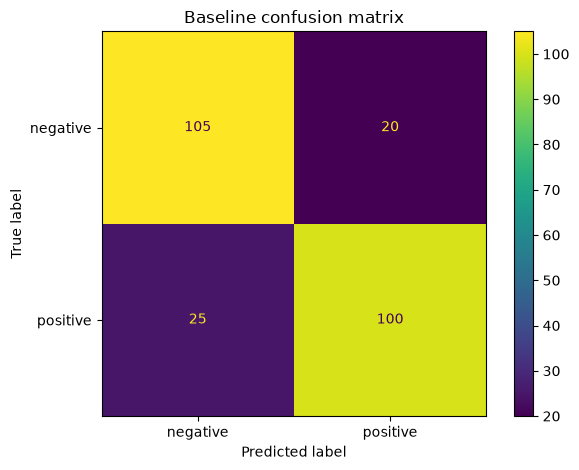

In [15]:
# Baseline confusion matrix
cm = confusion_matrix(y_test, baseline_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["negative", "positive"])
disp.plot()
plt.title("Baseline confusion matrix")
plt.tight_layout()
plt.show()

**Think like an ML Systems engineer:**  
What exact artifacts would you save after fitting this pipeline so that inference can be reproduced later?      
I would save the trained Pipeline, including the fitted TF-IDF vectorizer and Logistic Regression model. I would also save the preprocessing configuration, random seed, training dataset version, Python and package versions, model parameters, and evaluation metrics.



### Post-execution interpretation questions

1. Which error type is more costly in a review-monitoring system: false negatives or false positives for negative sentiment?        
False negatives could be more costly because they cause genuinely negative reviews to be classified as positive. This could hide customer problems from a monitoring system. However, the actual cost depends on the organization's goals.


2. What does the confusion matrix reveal that accuracy alone does not?          
The confusion matrix shows the individual counts of true positives, true negatives, false positives, and false negatives. Accuracy only gives the overall proportion of correct predictions and does not show which type of mistake the model makes.


3. Why is this still only a baseline even if the metrics are strong?        
The model uses only unigram TF-IDF features and a relatively simple classifier. It may still struggle with phrases, negation, sarcasm, domain changes, and other forms of context.


### Step 8 — Improvement Step and Diagnostics

### Pre-coding questions

1. Why should bigrams help sentiment modeling more directly than unigrams alone?        
Bigrams capture short phrases such as "not good," "very good," or "poor quality." These phrases contain contextual information that individual words may not capture.


2. What happens when `min_df` is set too low?       
More rare words and phrases remain in the vocabulary. This can increase memory usage, sparsity, and noise, and may make the model more difficult to train.


3. What risk arises when `max_df` is set too aggressively?      
Useful words that happen to occur frequently can be removed. This can eliminate important information from the model.



### Function/class selection and parameter exploration

Use:

- `TfidfVectorizer`
- `LogisticRegression`
- `Pipeline`

Explore:

- `ngram_range=(1, 2)`
- `min_df`
- `max_df`
- `C`

Explain the effect of:

- `ngram_range` on context capture
- `min_df` on rare-feature pruning
- `max_df` on boilerplate suppression
- feature coefficients on interpretability and debugging

In [16]:
# Step 8A: Improved pipeline
improved_clf = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        stop_words=list(custom_stopwords)
    )),
    ("clf", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

improved_clf.fit(X_train_text, y_train)
improved_pred = improved_clf.predict(X_test_text)

print("Improved accuracy:", round(accuracy_score(y_test, improved_pred), 3))
print("Improved macro-F1:", round(f1_score(y_test, improved_pred, average="macro"), 3))
print("\nImproved classification report:\n")
print(classification_report(y_test, improved_pred, digits=3))

Improved accuracy: 0.816
Improved macro-F1: 0.816

Improved classification report:

              precision    recall  f1-score   support

           0      0.802     0.840     0.820       125
           1      0.832     0.792     0.811       125

    accuracy                          0.816       250
   macro avg      0.817     0.816     0.816       250
weighted avg      0.817     0.816     0.816       250



In [17]:
# Step 8B: Inspect influential features and misclassifications
tfidf_model = improved_clf.named_steps["tfidf"]
logreg_model = improved_clf.named_steps["clf"]

feature_names = np.array(tfidf_model.get_feature_names_out())
coef = logreg_model.coef_[0]

top_positive_idx = np.argsort(coef)[-15:][::-1]
top_negative_idx = np.argsort(coef)[:15]

top_positive_terms = list(feature_names[top_positive_idx])
top_negative_terms = list(feature_names[top_negative_idx])

print("Most positive terms:", top_positive_terms)
print("Most negative terms:", top_negative_terms)

error_df = pd.DataFrame({
    "text": X_test_text,
    "true_label": y_test,
    "pred_label": improved_pred
})
error_df = error_df[error_df["true_label"] != error_df["pred_label"]].copy()

print("\nNumber of errors:", len(error_df))
print(error_df.head(10).to_string(index=False))

Most positive terms: ['great', 'good', 'works', 'well', 'excellent', 'best', 'love', 'nice', 'comfortable', 'price', 'recommend', 'happy', 'easy', 'pleased', 'better']
Most negative terms: ['not', 'poor', 'bad', 'disappointed', 'first', 'worst', 'waste', 'horrible', 'unreliable', 'money', 'difficult', 'work', 'crap', 'none', 'return']

Number of errors: 46
                                                                                                                                             text  true_label  pred_label
My experience was terrible..... This was my fourth bluetooth headset, and while it was much more comfortable than my last Jabra (which I HATED!!!           0           1
                                                                                  Arrived quickly and much less expensive than others being sold.           1           0
                                                        I have yet to run this new battery below two bars and that's three days wit


### Post-execution interpretation questions

1. Did the improved model help all metrics equally? Why or why not?         
Not necessarily. Accuracy and macro-F1 measure different aspects of performance, so one can improve more than the other. Adding bigrams can help some mistakes while introducing additional sparse features that do not improve every metric.


2. Which influential terms look semantically meaningful, and which might be spurious?       
Terms that clearly express positive or negative opinions are likely meaningful. Terms that are product-specific, unusually common, or unrelated to sentiment may be spurious and could reflect quirks of the training data.


3. What limitations remain after adding bigrams?        
Bigrams still cannot fully understand longer context, sarcasm, complex grammar, or the relationship between words across longer sentences. They can also increase the number of features and computational cost.


4. If memory or latency were constrained, which version of the model would you prefer?          
I would prefer the unigram baseline because it has a smaller feature space and should require less memory and computation. I would use the bigram version if its improvement in performance justified the additional cost.



**Think like an ML Systems engineer:**  
What would you log in production to detect vocabulary drift, performance regression, or unexpected increases in inference cost?     
I would log vocabulary statistics, new and unseen terms, prediction distributions, confidence scores if available, latency, memory usage, error rates, and model performance when labeled data becomes available. I would also monitor changes in the frequency of important features.

### Step 9 — Topic Modeling with NMF

### Pre-coding questions

1. Why is NMF often a strong choice for short review text in a teaching lab?        
NMF works naturally with nonnegative TF-IDF representations and can produce interpretable groups of terms. This makes it useful for demonstrating how documents can be organized into latent topics.


2. What does the number of topics `K` control conceptually?         
K controls how many different topics the model attempts to identify. A smaller value produces broader topics, while a larger value can produce more specific or fragmented topics.


3. Why should topic labels be treated as hypotheses rather than ground truth?       
NMF discovers statistical patterns in the words rather than receiving human-defined topic labels. The resulting topics need to be interpreted and validated by a person.



### Function/class selection and parameter exploration

Use:

- `TfidfVectorizer`
- `NMF`

Explore:

- `NMF(n_components, init, random_state, max_iter)`
- `TfidfVectorizer(min_df, max_df, ngram_range)`

Explain the effect of:

- `n_components` on broad vs fragmented themes
- `init="nndsvda"` on stability
- `max_iter` on convergence
- vocabulary filtering on topic coherence

In [18]:
# Step 9: Topic modeling with NMF
topic_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words=list(custom_stopwords),
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.90
)

X_topics = topic_vectorizer.fit_transform(df["text"])
topic_terms = topic_vectorizer.get_feature_names_out()

K = 6
nmf = NMF(
    n_components=K,
    init="nndsvda",
    max_iter=500,
    random_state=RANDOM_STATE
)

W = nmf.fit_transform(X_topics)
H = nmf.components_

def top_terms_for_topic(H, terms, topic_idx, topn=10):
    idx = np.argsort(H[topic_idx])[-topn:][::-1]
    return [terms[i] for i in idx]

for k in range(K):
    print(f"Topic {k}: {top_terms_for_topic(H, topic_terms, k, topn=10)}")

Topic 0: ['phone', 'great phone', 'like', 'new', 'best', 'cell phone', 'get', 'cell', 'even', 'excellent']
Topic 1: ['not', 'work', 'not work', 'would', 'not good', 'enough', 'buy', 'charger', 'item', 'would not']
Topic 2: ['good', 'product', 'price', 'case', 'good product', 'not good', 'good quality', 'far', 'really', 'happy']
Topic 3: ['sound', 'quality', 'headset', 'sound quality', 'excellent', 'poor', 'service', 'clear', 'ear', 'bluetooth']
Topic 4: ['great', 'works', 'works great', 'great phone', 'great product', 'item', 'fine', 'works fine', 'device', 'price']
Topic 5: ['battery', 'life', 'waste', 'battery life', 'money', 'waste money', 'disappointed', 'time', 'long', 'well']


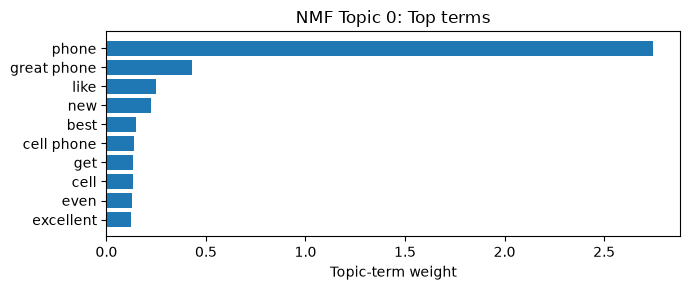

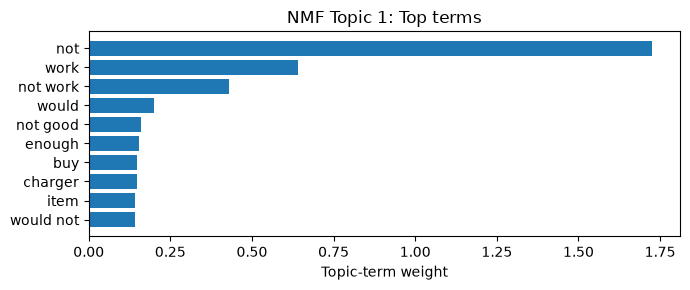

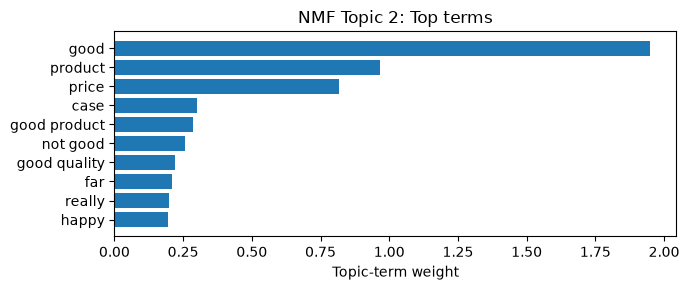

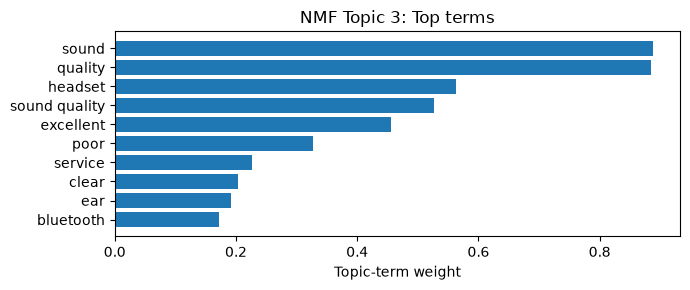

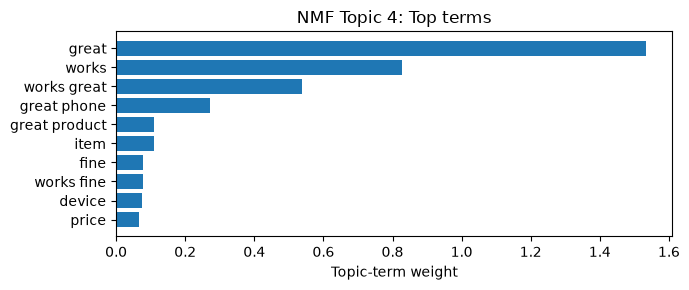

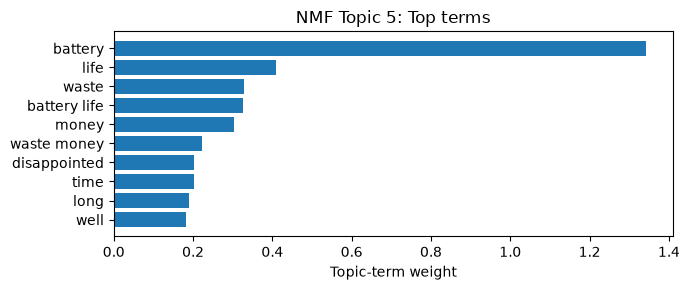

In [19]:
# Topic-term bar plots
for k in range(K):
    top_idx = np.argsort(H[k])[-10:][::-1]
    terms = topic_terms[top_idx][::-1]
    weights = H[k][top_idx][::-1]

    plt.figure(figsize=(7, 3))
    plt.barh(terms, weights)
    plt.title(f"NMF Topic {k}: Top terms")
    plt.xlabel("Topic-term weight")
    plt.tight_layout()
    plt.show()

In [20]:
# Exemplar documents per topic
for k in range(K):
    top_doc_idx = np.argsort(W[:, k])[-5:][::-1]
    print(f"\n=== Topic {k} ===")
    print("Top terms:", top_terms_for_topic(H, topic_terms, k, topn=8))
    print("Exemplar reviews:")
    for i in top_doc_idx:
        print("-", df.iloc[i]["text"])


=== Topic 0 ===
Top terms: ['phone', 'great phone', 'like', 'new', 'best', 'cell phone', 'get', 'cell']
Exemplar reviews:
- SWEETEST PHONE!!!
- Were JERKS on the phone.
- Protects the phone on all sides.
- My phone doesn't slide around my car now and the grip prevents my phone from slipping out of my hand.
- however, my girl was complain that some time the phone doesn't wake up like normal phone does.

=== Topic 1 ===
Top terms: ['not', 'work', 'not work', 'would', 'not good', 'enough', 'buy', 'charger']
Exemplar reviews:
- Its not user friendly.
- It's not what it says it is.
- Does Not Work.
- Just does not work.
- Does not work for listening to music with the cingular 8125.

=== Topic 2 ===
Top terms: ['good', 'product', 'price', 'case', 'good product', 'not good', 'good quality', 'far']
Exemplar reviews:
- Very good stuff for the price.
- Good price.
- Price is good too.
- Good product, good seller.
- The price was very good and with the free shipping and all it was a good purchas

### Post-execution interpretation questions

1. Which topics appear coherent and which appear mixed or weak?         
A coherent topic will have top terms that clearly relate to some common theme or subject, and the exemplar reviews for that topics should also reflect that theme. A mixed or weak topic would have unrelated terms and/or reviews that don't clearly share a common theme. The exact topics should be determined by what the NMF actually outputs.


2. How would increasing `K` from 6 to 10 likely change the results?         
The model would identify more topics, so broad themes could be divided into smaller and more specific groups. However, some additional topics could be weak, overlapping, or difficult to interpret.


3. Why are exemplar documents necessary in addition to top terms?           
Top terms only show the words associated with a topic. Exemplar reviews provide actual context and help determine whether those words really represent a coherent topic.


### Step 10 — Sentiment-by-Topic Reporting and Systems Discussion

### Pre-coding questions

1. Why is soft topic assignment preferable to hard assignment for sentiment-by-topic summaries?         
A review can discuss multiple topics at the same time. Soft assignment preserves the degree to which a review belongs to each topic instead of forcing it into only one category.


2. What can go wrong if executives see only topic labels but not exemplar reviews?          
They may interpret the automatically generated topic names as facts even when the topic is mixed or ambiguous. Without example reviews, they have less context for determining whether the topic actually represents the business issue being described.


3. Which drift signals would matter most if this pipeline were deployed on new product lines?       
Important signals include changes in vocabulary, topic prevalence, sentiment distributions, prediction behavior, and the appearance of new product-specific terms. Increases in errors or manual-review rates would also be important.



### Function/class selection and parameter exploration

Use:

- `Pipeline.predict`
- row normalization of NMF document-topic weights

Explore:

- normalized topic weights vs hard assignment
- predicted labels vs true labels in dashboards
- topic count and exemplar count

Explain the effect of:

- row-normalizing `W` on interpretability
- using predicted sentiment instead of true labels
- exemplar count on human validation quality

In [21]:
# Step 10: Sentiment-by-topic summary
full_pred = improved_clf.predict(df["text"].astype(str).values)

W_row_sums = W.sum(axis=1, keepdims=True)
W_mix = W / np.where(W_row_sums == 0, 1.0, W_row_sums)

# Negativity rate per topic:
# NegRate(k) = sum_d W_mix[d, k] * I(predicted negative) / sum_d W_mix[d, k]
neg_rates = []
for k in range(K):
    weights_k = W_mix[:, k]
    denom = weights_k.sum()
    neg_rate_k = float((weights_k * (full_pred == 0)).sum() / denom) if denom > 0 else np.nan
    neg_rates.append(neg_rate_k)

topic_summary = pd.DataFrame({
    "topic": list(range(K)),
    "negativity_rate": neg_rates,
    "top_terms": [", ".join(top_terms_for_topic(H, topic_terms, k, topn=8)) for k in range(K)]
}).sort_values("negativity_rate", ascending=False)

print(topic_summary.round(3).to_string(index=False))

 topic  negativity_rate                                                                     top_terms
     1            0.757                    not, work, not work, would, not good, enough, buy, charger
     5            0.685    battery, life, waste, battery life, money, waste money, disappointed, time
     0            0.532                    phone, great phone, like, new, best, cell phone, get, cell
     3            0.497       sound, quality, headset, sound quality, excellent, poor, service, clear
     2            0.319         good, product, price, case, good product, not good, good quality, far
     4            0.132 great, works, works great, great phone, great product, item, fine, works fine


In [22]:
# Most negative topic: inspect exemplar documents
worst_topic = int(topic_summary.iloc[0]["topic"])
top_doc_idx = np.argsort(W_mix[:, worst_topic])[-8:][::-1]

print(f"Most negative topic: Topic {worst_topic}")
print("Top terms:", top_terms_for_topic(H, topic_terms, worst_topic, topn=10))
print("\nExemplar reviews:")
for i in top_doc_idx:
    print(f"- [{int(full_pred[i])}] {df.iloc[i]['text']}")

Most negative topic: Topic 1
Top terms: ['not', 'work', 'not work', 'would', 'not good', 'enough', 'buy', 'charger', 'item', 'would not']

Exemplar reviews:
- [0] Its not user friendly.
- [0] The holster that arrived did not match the photo in the ad.
- [0] Soyo technology sucks.
- [0] Not worth it.
- [0] Because both ears are occupied, background is not distracting at all.
- [0] Does not fit.
- [0] This particular model would not work with my Motorola Q smartphone.
- [0] Does not fit.


**Think like an ML Systems engineer:**  
What would you monitor weekly in production? Consider vocabulary drift, score drift, topic prevalence shifts, latency, failed transforms, and manual audit triggers.        
I would monitor vocabulary drift, changes in sentiment scores, shifts in topic prevalence, inference latency, failed preprocessing steps, and manually reviewed examples. I would set alerts for large changes in vocabulary or topic distributions, increased latency or transform failures, and cases where the model's predictions do not match human audits.


### Post-execution interpretation questions

1. Does the most negative topic look plausible based on its exemplar documents?         
It should be considered plausible only if the exemplar reviews actually contain a consistent negative theme. The topic terms alone are not enough to make this determination.

2. What limitation arises from using model-predicted sentiment rather than human labels in the dashboard?           
The sentiment-by-topic results can contain errors from the classifier. If the classifier incorrectly labels reviews, those errors will also affect the reported negativity rate for each topic.

 
3. How would you communicate this result responsibly to a nontechnical stakeholder?         
I would explain that the topics and sentiment rates are model-generated summaries rather than definitive categories. I would show representative reviews and explain that the results should be used to identify areas for investigation rather than treated as perfect measurements.


4. What is the next improvement you would prioritize in a production version of this system?        
I would prioritize collecting human-labeled production reviews and using them to evaluate and improve the sentiment model. I would also monitor domain-specific vocabulary and retrain the system when performance or data distributions change.


#  Reflection

1. Which information could be destroyed by indiscriminate stopword removal?         
Stopword removal can remove important contextual and sentiment information, especially negation words such as "not," "no," and "never." This can change the meaning of a review and cause incorrect sentiment predictions.

2. Why must the vectorizer be fit on the training split only?       
The vectorizer learns the vocabulary and IDF values from the data. If it is fitted using the test set, information from the test data enters the modeling process and creates leakage. Fitting it only on the training data keeps the evaluation leakage-safe.

3. Which model would you deploy first under a tight latency budget, and why?        
I would start with the unigram TF-IDF plus Logistic Regression model. It is relatively simple, fast, and uses a smaller feature space than the bigram version. If the bigram model provides a meaningful improvement that justifies the additional latency and memory, I would consider switching to it.

4. Which result in this notebook would you trust least without additional human review?         
I would trust automatically generated NMF topic labels and sentiment-by-topic summaries the least. The topics are found using statistical patterns of words, and the sentiment-by-topic results are based on the predicted sentiment, which was not necessarily checked by humans. The lab specifically focuses on exemplar documents and human interpretation when analyzing topics.


**End of Lab**